In [14]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d

In [15]:
import seaborn as sns

In [16]:
def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    #eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]

    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)

    print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")

def plot_distributions(scores, labels, lbound=None, hbound=None, thr=0, ax=None, metrics=True):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    if metrics:
        print_metrics(scores, labels)
        #print(f"Loaded {len(scores)} samples")
        #print(f"Real mean score: {real_scores.mean():.4f}")
        #print(f"Fake mean score: {fake_scores.mean():.4f}\n")
        
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    sns.kdeplot(real_scores, fill=True, alpha=0.5, label="Real (0)", ax=ax)
    sns.kdeplot(fake_scores, fill=True, alpha=0.5, label="Fake (1)", ax=ax)
    #sns.histplot(real_scores, bins=50, stat="count", kde=False, color='blue', alpha=0.4, label="Real (0)", ax=ax)
    #sns.histplot(fake_scores, bins=50, stat="count", kde=False, color='orange', alpha=0.4, label="Fake (1)", ax=ax)

    ax.axvline(thr, linestyle="--", linewidth=2, color="red")
    
    if lbound is not None:
        ax.axvspan(lbound, hbound, color="yellow", alpha=0.3)
        
    ax.legend()


def plot_raw_scatter(scores, labels, ax=None, metrics=True):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    if metrics:
        print_metrics(scores, labels)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    real_y = np.zeros_like(real_scores)
    fake_y = np.ones_like(fake_scores)

    ax.scatter(real_scores, real_y, alpha=0.5, label="Real (0)")
    ax.scatter(fake_scores, fake_y, alpha=0.5, label="Fake (1)")
    ax.set_xlabel("Score")
    ax.set_ylabel("Label")
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Real", "Fake"])
    ax.legend()


def print_expert_stats(name, idx, raw, scaled):
    print(f"{name} (idx={idx})")
    print("-" * 40)

    print("Raw logits")
    print(f"  std: {np.std(raw[idx]):.4f}")
    print(f"  min/max: {raw[idx].min():.4f} / {raw[idx].max():.4f}")

    print("\nScaled logits")
    print(f"  std: {np.std(scaled[idx]):.6f}")
    print(f"  min/max: {scaled[idx].min():.6f} / {scaled[idx].max():.6f}")

    print()


def plot_platt(a, b, logits, ax=None, title=""):
    if ax is None:
        ax = plt.gca()

    # Full sigmoid
    z_full = np.linspace(-10, 10, 1000)
    p_full = 1 / (1 + np.exp(-(a * z_full + b)))

    # Data range
    z_min, z_max = logits.min(), logits.max()
    z_data = np.linspace(z_min, z_max, 500)
    p_data = 1 / (1 + np.exp(-(a * z_data + b)))

    # Min/max points
    p_min = 1 / (1 + np.exp(-(a * z_min + b)))
    p_max = 1 / (1 + np.exp(-(a * z_max + b)))

    # Plot on given axis
    ax.plot(z_full, p_full, label="Full sigmoid", alpha=0.5)
    ax.plot(z_data, p_data, linewidth=3, label="Used region")
    ax.scatter([z_min, z_max], [p_min, p_max], color="red", zorder=3, label="min/max raw logits")
    ax.axvline(z_min, linestyle="--", alpha=0.5)
    ax.axvline(z_max, linestyle="--", alpha=0.5)
    ax.set_xlabel("logits (z)")
    ax.set_ylabel("probability")
    ax.set_title(title)
    #ax.legend()
    ax.grid()


# Test set: ASVspoof 2019

In [10]:
generator_list = ['A04']

score_types = [
    ("LogLR scores", "scores_per_expert.npy"),
    ("Scaled Logits", "scaled_logits_per_expert.npy"),
    ("Raw Logits", "raw_logits_per_expert.npy"),
]


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 54.70%, EER: 44.50%


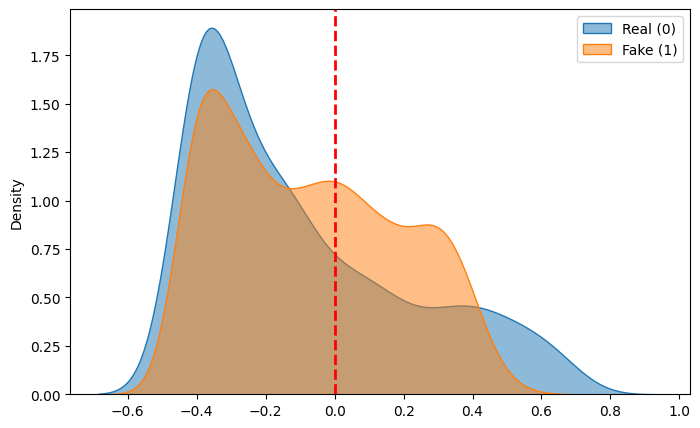


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 54.53%, EER: 44.40%


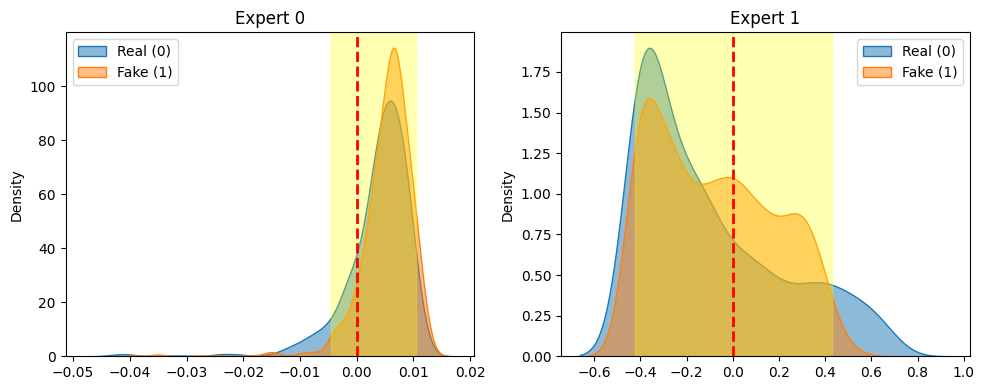


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 76.68%, EER: 30.50%


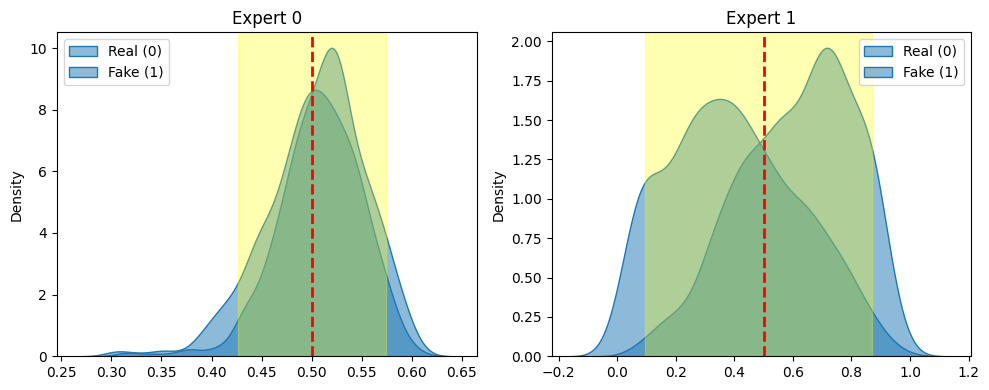


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 76.68%, EER: 30.50%


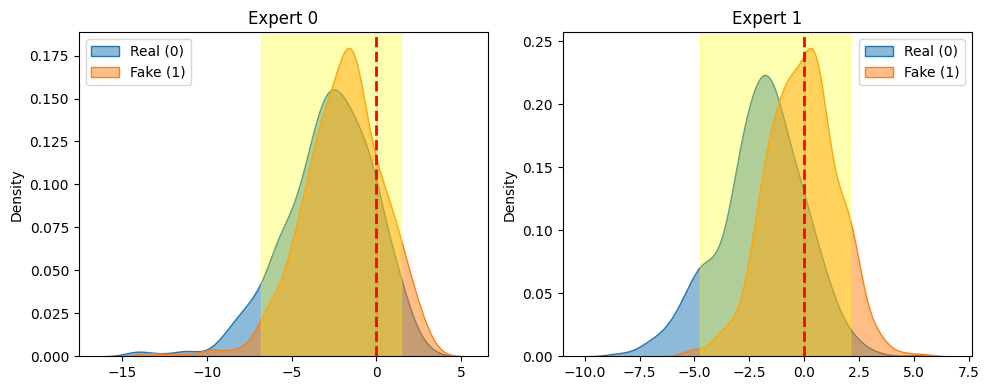

In [11]:
for g in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {g} {'-'*57}#")
    print(f"{'#'*120}\n")
                    
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/temp/trials/{g}"

    # -------- ENSEMBLE --------
    print("\n#--------- OVERALL ENSEMBLE (sum LogLR) ---------#\n")
    scores = np.load(os.path.join(rootpath, "scores.npy"))
    labels = np.load(os.path.join(rootpath, "labels.npy"))
    plot_distributions(scores, labels)
    plt.show()

    # -------- PER EXPERT --------
    for title, filename in score_types:
        print(f"\n#------------ PER EXPERT ({title}) ------------#\n")

        all_scores = np.load(os.path.join(rootpath, filename))
        n_exp = all_scores.shape[0]

        fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

        for i in range(n_exp):
            ax = axes[i] if n_exp > 1 else axes
            scores = all_scores[i]

            if title == "Scaled Logits":
                thr = 0.5
            else:
                thr = 0

            lbound = np.percentile(scores, 5)
            hbound = np.percentile(scores, 95)

            plot_distributions(scores, labels, lbound, hbound, thr=thr, ax=ax, metrics=True)
            # plot_raw_scatter(scores, labels, ax=ax, metrics=False)

            ax.set_title(f"Expert {i}")

        plt.tight_layout()
        plt.show()

In [8]:
generator_list = ['A04']


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 23.38%, EER: 69.44%


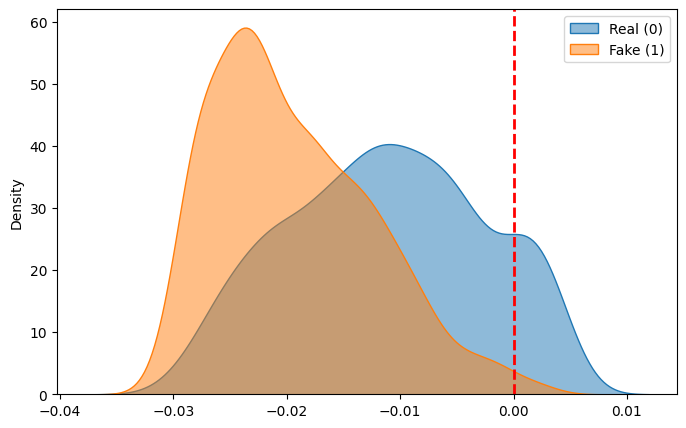


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 23.32%, EER: 69.50%


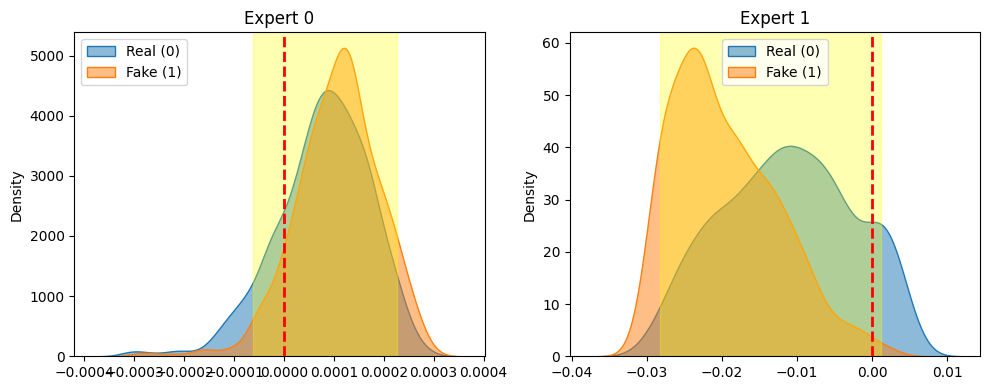


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 76.68%, EER: 30.50%


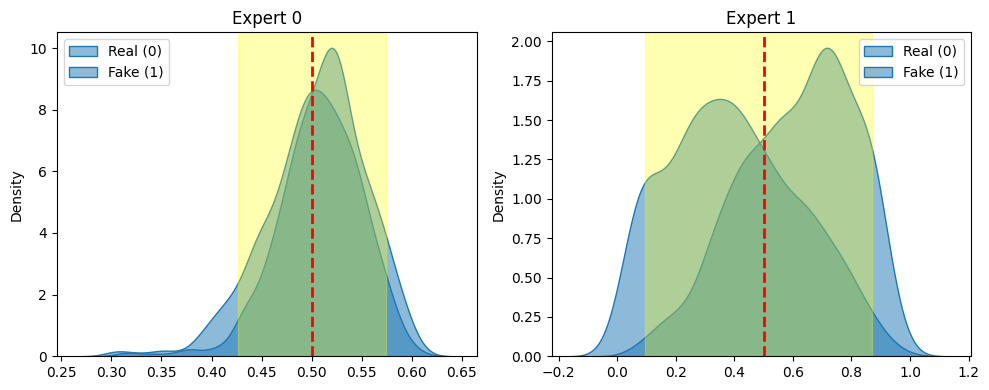


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 76.68%, EER: 30.50%


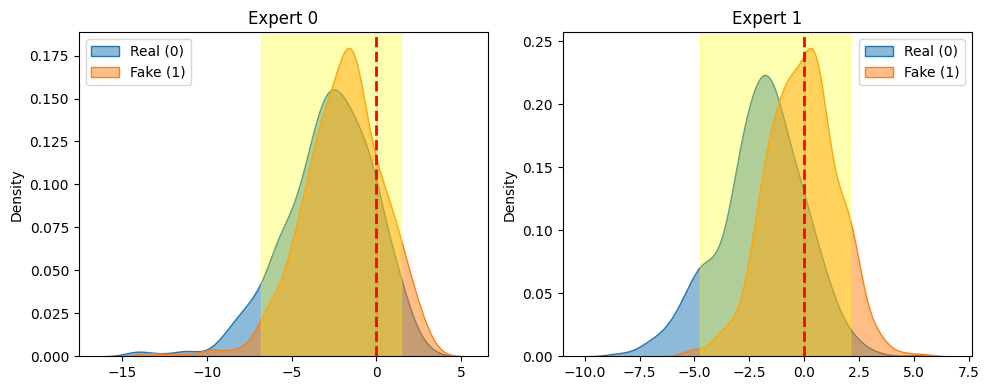

In [9]:
for g in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {g} {'-'*57}#")
    print(f"{'#'*120}\n")
                    
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/temp/trials2/{g}"

    # -------- ENSEMBLE --------
    print("\n#--------- OVERALL ENSEMBLE (sum LogLR) ---------#\n")
    scores = np.load(os.path.join(rootpath, "scores.npy"))
    labels = np.load(os.path.join(rootpath, "labels.npy"))
    plot_distributions(scores, labels)
    plt.show()

    # -------- PER EXPERT --------
    for title, filename in score_types:
        print(f"\n#------------ PER EXPERT ({title}) ------------#\n")

        all_scores = np.load(os.path.join(rootpath, filename))
        n_exp = all_scores.shape[0]

        fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

        for i in range(n_exp):
            ax = axes[i] if n_exp > 1 else axes
            scores = all_scores[i]

            if title == "Scaled Logits":
                thr = 0.5
            else:
                thr = 0

            lbound = np.percentile(scores, 5)
            hbound = np.percentile(scores, 95)

            plot_distributions(scores, labels, lbound, hbound, thr=thr, ax=ax, metrics=True)
            # plot_raw_scatter(scores, labels, ax=ax, metrics=False)

            ax.set_title(f"Expert {i}")

        plt.tight_layout()
        plt.show()


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 77.21%, EER: 30.14%


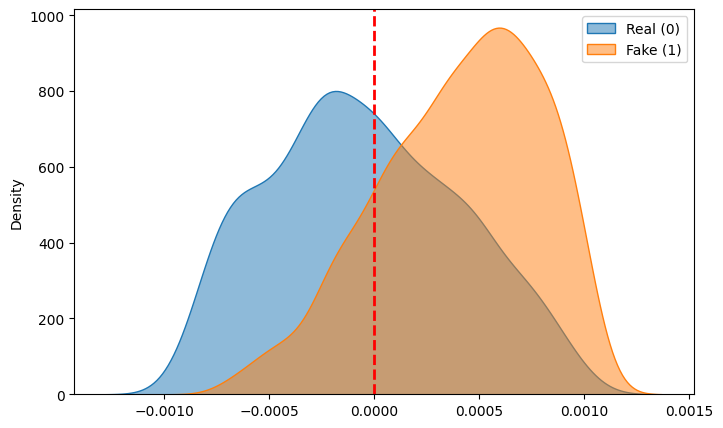


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 76.68%, EER: 30.50%


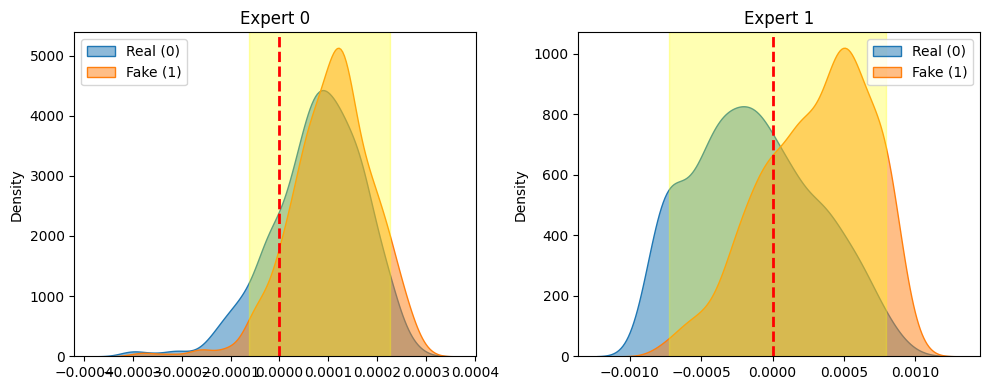


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 76.68%, EER: 30.50%


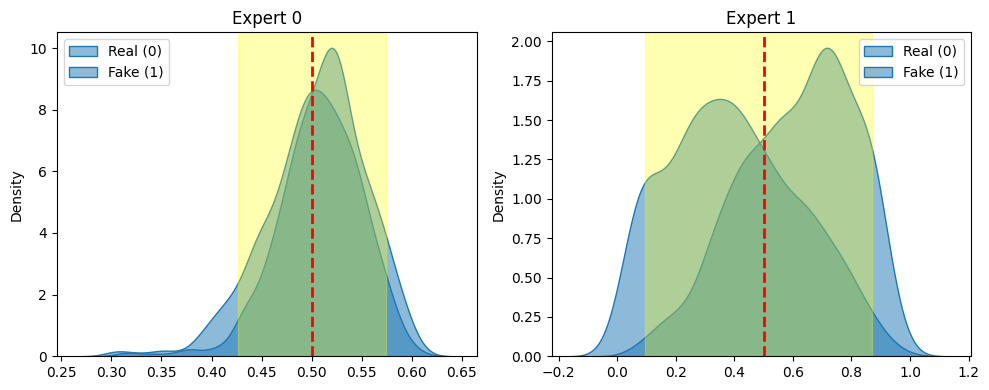


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 76.68%, EER: 30.50%


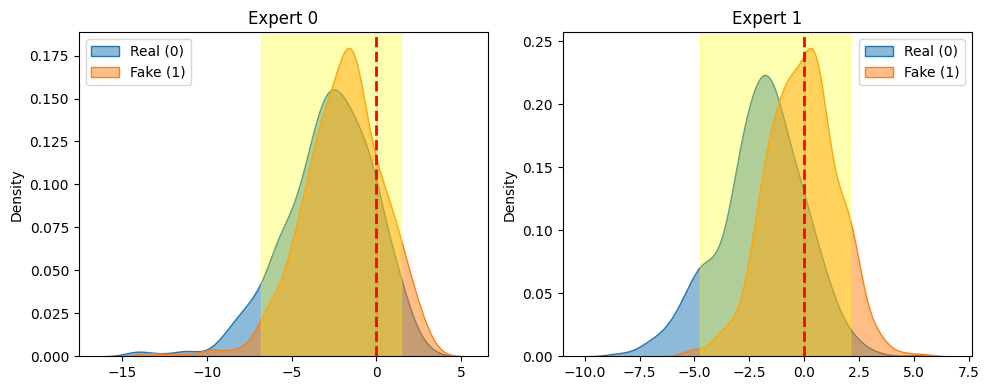

In [12]:
for g in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {g} {'-'*57}#")
    print(f"{'#'*120}\n")
                    
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/temp/trials3/{g}"

    # -------- ENSEMBLE --------
    print("\n#--------- OVERALL ENSEMBLE (sum LogLR) ---------#\n")
    scores = np.load(os.path.join(rootpath, "scores.npy"))
    labels = np.load(os.path.join(rootpath, "labels.npy"))
    plot_distributions(scores, labels)
    plt.show()

    # -------- PER EXPERT --------
    for title, filename in score_types:
        print(f"\n#------------ PER EXPERT ({title}) ------------#\n")

        all_scores = np.load(os.path.join(rootpath, filename))
        n_exp = all_scores.shape[0]

        fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

        for i in range(n_exp):
            ax = axes[i] if n_exp > 1 else axes
            scores = all_scores[i]

            if title == "Scaled Logits":
                thr = 0.5
            else:
                thr = 0

            lbound = np.percentile(scores, 5)
            hbound = np.percentile(scores, 95)

            plot_distributions(scores, labels, lbound, hbound, thr=thr, ax=ax, metrics=True)
            # plot_raw_scatter(scores, labels, ax=ax, metrics=False)

            ax.set_title(f"Expert {i}")

        plt.tight_layout()
        plt.show()


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 76.87%, EER: 30.50%


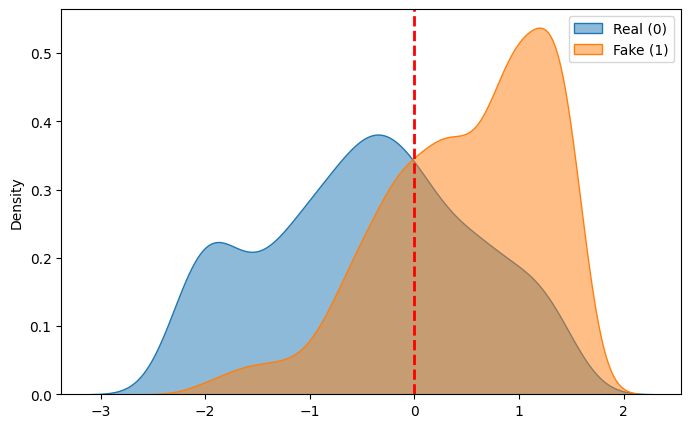


#------------ PER EXPERT (LogLR scores) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 76.68%, EER: 30.50%


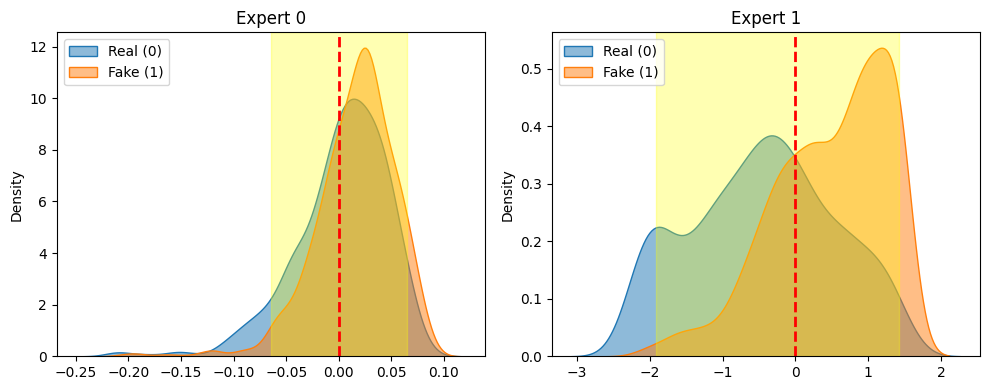


#------------ PER EXPERT (Scaled Logits) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 76.68%, EER: 30.50%


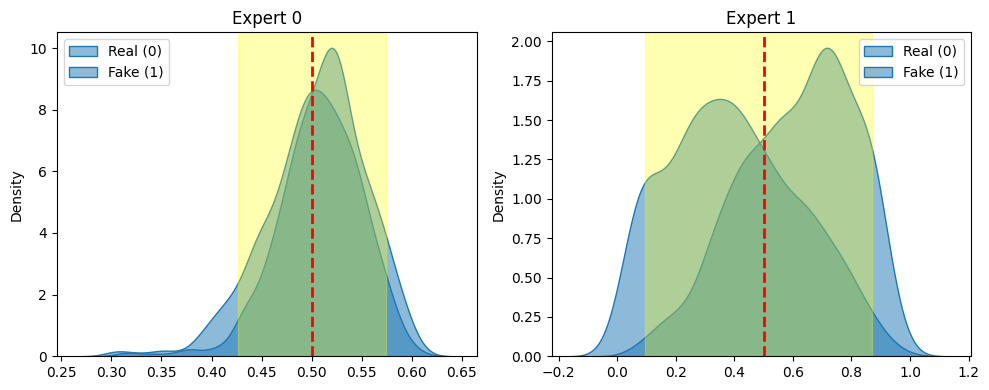


#------------ PER EXPERT (Raw Logits) ------------#

AUC: 58.56%, EER: 43.34%
AUC: 76.68%, EER: 30.50%


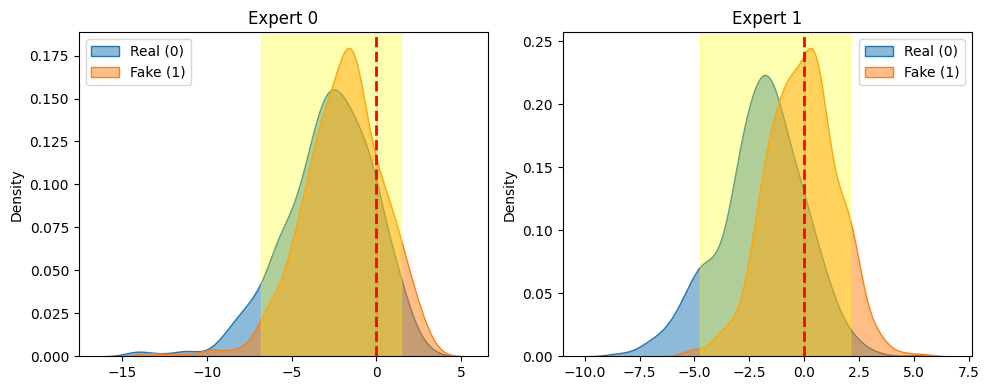

In [17]:
for g in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {g} {'-'*57}#")
    print(f"{'#'*120}\n")
                    
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/temp/trials5/{g}"

    # -------- ENSEMBLE --------
    print("\n#--------- OVERALL ENSEMBLE (sum LogLR) ---------#\n")
    scores = np.load(os.path.join(rootpath, "scores.npy"))
    labels = np.load(os.path.join(rootpath, "labels.npy"))
    plot_distributions(scores, labels)
    plt.show()

    # -------- PER EXPERT --------
    for title, filename in score_types:
        print(f"\n#------------ PER EXPERT ({title}) ------------#\n")

        all_scores = np.load(os.path.join(rootpath, filename))
        n_exp = all_scores.shape[0]

        fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

        for i in range(n_exp):
            ax = axes[i] if n_exp > 1 else axes
            scores = all_scores[i]

            if title == "Scaled Logits":
                thr = 0.5
            else:
                thr = 0

            lbound = np.percentile(scores, 5)
            hbound = np.percentile(scores, 95)

            plot_distributions(scores, labels, lbound, hbound, thr=thr, ax=ax, metrics=True)
            # plot_raw_scatter(scores, labels, ax=ax, metrics=False)

            ax.set_title(f"Expert {i}")

        plt.tight_layout()
        plt.show()